# Proyecto Integrador de Ciencia de Datos e Inteligencia Artificial
## Entregable 1 · Planteamiento del problema, descripción del dataset y EDA

**Universidad de La Salle · Facultad de Ingeniería · Maestría en Inteligencia Artificial**
**Asignatura:** Ciencia de Datos · **Docente:** Fabián Camilo Castro Riveros
**Integrantes:** Tony Yu, Luis Rodríguez, Maydda Rodríguez
**Dataset:** Metro Interstate Traffic Volume (UCI Machine Learning Repository)

---

**Estructura del cuaderno** (sigue la sección 3.1 de la Guía Técnica Detallada):

1. Formulación del problema y objetivos
2. Ficha técnica, diccionario de datos y método de análisis
3. Diagnóstico de calidad de datos
4. Análisis univariado
5. Análisis bivariado y multivariado
6. Conclusiones del EDA y decisiones para la Fase 2
7. Lista de verificación frente a la guía
8. Referencias (APA, 7.ª edición)

El cuaderno acompaña al informe en Word con normas APA (*Entregable1_Informe_APA.docx*); ambos usan las mismas cifras y las mismas decisiones.

**Cómo ejecutarlo:** el cuaderno vive en `notebooks/` del repositorio y se ejecuta desde esa carpeta (*Kernel → Restart & Run All*). Lee `../data/raw/Metro_Interstate_Traffic_Volume.csv`; si no existe, intenta descargarlo desde UCI. Todos los números y las lecturas de resultados se calculan en el propio cuaderno.

## Resumen

Este cuaderno presenta la primera fase del proyecto integrador: la formulación del problema, la descripción del conjunto de datos y su análisis exploratorio. Se trabajó con *Metro Interstate Traffic Volume* (Hogue, 2019), que registra por hora el volumen de tráfico en sentido oeste de la autopista I-94 (Minnesota, Estados Unidos) entre 2012 y 2018, junto con variables meteorológicas y festivos. Se formularon una pregunta principal, tres preguntas secundarias y un objetivo general con tres objetivos específicos en formato SMART. El conjunto tiene 48.204 filas y 9 columnas, equivalentes a 40.575 horas distintas. El diagnóstico de calidad encontró 17 filas duplicadas, 7.612 filas que repiten una hora con distinto reporte climático, 11 valores físicamente imposibles y una ausencia del 22,8 % de las horas del periodo, concentrada en 2014 y 2015. El volumen sigue un patrón de calendario: la hora del día explica el 78,2 % de su varianza (η² = 0,782), frente al 2,1 % del tipo de clima. El perfil horario difiere entre días laborales y fines de semana, y los festivos entre semana tienen en promedio 1.042 vehículos por hora menos que los días laborales normales. El nivel de tráfico (bajo, medio, alto) resultó razonablemente balanceado (razón entre clases de 1,36) y un K-means exploratorio mostró una estructura de grupos débil (silueta máxima de 0,289).

*Palabras clave:* volumen de tráfico, análisis exploratorio de datos, calidad de datos, series horarias, estacionalidad.

*Nota.* Las cifras de este resumen corresponden a la ejecución con el archivo de UCI; las celdas de resultados las recalculan en cada ejecución.

In [1]:
import io, gzip, sys, zipfile, urllib.request, warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)

# ---- Estilo: un color principal con significado, pares aptos para daltonismo
COLOR, COLOR2, GRIS = "#6B5FAF", "#E08E45", "#8C8C8C"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.labelsize": 10, "figure.dpi": 110})

def fmt(x, d=2):
    """Formato numérico español: 1.234,56"""
    s = f"{x:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def fmt_p(p):
    return "< 0,001" if p < 0.001 else fmt(p, 3)

def miles(ax, eje="y"):
    f = FuncFormatter(lambda v, _: fmt(v, 0))
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(f)

def nota(texto):
    display(Markdown(texto))

pd.set_option("display.float_format", lambda v: fmt(v, 2))
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", None)

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", __import__("scipy").__version__, "| seaborn", sns.__version__)

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scipy 1.18.1 | seaborn 0.13.2


---
# 1. Formulación del problema y objetivos

## 1.1 Contextualización e impacto potencial

La Interstate 94 (I-94) conecta Minneapolis y Saint Paul (Minnesota). El dataset recoge, hora a hora, el volumen de tráfico en sentido **oeste (westbound)** medido por la estación de conteo automático (ATR) 301 del Departamento de Transporte de Minnesota, ubicada aproximadamente a mitad de camino entre ambas ciudades, junto con las condiciones meteorológicas de cada hora y los días festivos del periodo 2012-2018 (Hogue, 2019).

Anticipar el volumen horario de tráfico es un insumo para la gestión de la infraestructura vial. Una solución analítica que prediga el volumen, clasifique su nivel y segmente las horas de operación podría apoyar, por ejemplo, la información a los conductores y la respuesta ante incidentes en las horas de mayor demanda; la programación de obras y mantenimiento en las franjas de menor flujo; la preparación de la operación invernal, al medir cuánto cambia la demanda con lluvia, nieve o frío extremo; y la planeación de largo plazo, al identificar qué factores determinan la demanda. Estos usos son aplicaciones potenciales de la solución y no resultados de este informe.

## 1.2 Preguntas de investigación

**Pregunta principal.** ¿Con qué precisión puede predecirse el volumen horario de tráfico westbound de la I-94 a partir de variables de calendario y condiciones meteorológicas, y qué factores lo determinan en mayor medida?

**Preguntas secundarias.**

1. **(Patrones)** ¿Cómo varía el volumen según la hora, el día de la semana, el mes y los festivos, y en qué se diferencia el perfil horario de un día laboral del de un fin de semana?
2. **(Clima)** ¿Tienen la temperatura, la lluvia, la nieve, la nubosidad y el tipo de clima un efecto medible sobre el volumen una vez se considera el calendario?
3. **(Niveles y segmentos)** ¿Es posible clasificar cada hora en un nivel de tráfico (bajo, medio, alto) y descubrir, mediante clustering, segmentos de horas con comportamiento homogéneo?

## 1.3 Objetivos (formato SMART)

**Objetivo general.** Entre el 20 de octubre y el 28 de noviembre de 2026, desarrollar y desplegar una solución analítica de extremo a extremo sobre el dataset *Metro Interstate Traffic Volume* que **prediga** el volumen horario de tráfico (regresión), **clasifique** su nivel (bajo/medio/alto) y **segmente** las horas de operación (clustering), validada con partición Train/Validación/Prueba y presentada en un dashboard interactivo con los cuatro módulos obligatorios.

**Objetivos específicos.**

| # | Objetivo | Específico | Medible | Alcanzable | Relevante | Temporal |
|---|---|---|---|---|---|---|
| E1 | Preparar un conjunto de datos limpio y reproducible para modelar. | Tratar duplicados, valores imposibles, huecos de la serie y outliers; crear ≥ 2 variables derivadas; codificar y escalar sin fuga de datos. | Partición estratificada 70/15/15; ≥ 2 variables derivadas; baseline con R² y F1-macro de referencia. | Los problemas de calidad son puntuales (sección 3). | Sin datos depurados y sin fuga, las métricas posteriores no son válidas. | Hasta el 15 de noviembre de 2026 |
| E2 | Construir y comparar modelos supervisados. | ≥ 2 modelos de regresión (uno regularizado y uno de ensamble), ≥ 2 de clasificación y un MLP en PyTorch, con búsqueda de hiperparámetros por validación cruzada e interpretabilidad (SHAP/importancia). | **R² ≥ 0,90** y **F1-macro ≥ 0,92** en validación, superando al baseline. | El EDA (sección 5) permite verificar cuánta varianza explica el calendario; las metas se ajustan con el baseline de la Fase 2. | Responde la pregunta principal. | Hasta el 22 de noviembre de 2026 |
| E3 | Segmentar las horas y entregar el producto final. | K-Means (K elegido con codo y silueta) y un segundo algoritmo (DBSCAN o jerárquico); perfiles interpretados; dashboard desplegado con filtros, KPIs, predicción en vivo y mapa de clústeres. | Silueta reportada para cada K; 4 módulos funcionando en el despliegue; informe y repositorio con `requirements.txt`. | Frameworks permitidos por la guía (Streamlit, Dash, etc.). | Comunica los resultados a usuarios no técnicos. | Hasta el 28 de noviembre de 2026 |

*Nota.* Las metas numéricas de E2 son un compromiso propuesto por el equipo y se revisarán con los resultados del modelo de referencia de la Fase 2. En cuanto a su viabilidad (*alcanzable*), los problemas de calidad detectados en este informe son acotados y el análisis exploratorio muestra una señal de calendario fuerte; en cuanto a su pertinencia (*relevante*), E1 habilita todas las preguntas, E2 responde la pregunta principal y E3 la tercera pregunta secundaria.


---
# 2. Ficha técnica y diccionario de datos

In [2]:
RUTA = Path("../data/raw/Metro_Interstate_Traffic_Volume.csv")
URL_UCI = "https://archive.ics.uci.edu/static/public/492/metro+interstate+traffic+volume.zip"
descargado = False

if not RUTA.exists():
    RUTA.parent.mkdir(parents=True, exist_ok=True)
    try:
        with urllib.request.urlopen(URL_UCI, timeout=60) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        miembro = next(n for n in z.namelist() if n.endswith((".csv", ".csv.gz")))
        datos = z.read(miembro)
        if miembro.endswith(".gz"):
            datos = gzip.decompress(datos)
        RUTA.write_bytes(datos)
        descargado = True
    except Exception as e:
        raise FileNotFoundError(
            f"No se pudo descargar el dataset ({e}). Descárguelo manualmente desde "
            "https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume "
            f"y guárdelo como {RUTA}") from e

# Si conoce la fecha real en que se bajó el archivo, escríbala aquí (formato "dd/mm/aaaa"); si no, se usa la fecha del archivo local
FECHA_EXTRACCION_MANUAL = "10/11/2026"   # confirme la fecha real de descarga; si la deja en None se usa la fecha del archivo local
if FECHA_EXTRACCION_MANUAL:
    FECHA_EXTRACCION = datetime.strptime(FECHA_EXTRACCION_MANUAL, "%d/%m/%Y")
else:
    FECHA_EXTRACCION = datetime.now() if descargado else datetime.fromtimestamp(RUTA.stat().st_mtime)

# keep_default_na=False: el texto 'None' de 'holiday' es una categoría válida (día no festivo), no un faltante
df = pd.read_csv(RUTA, keep_default_na=False, na_values=[""])
df["date_time"] = pd.to_datetime(df["date_time"])

ficha = pd.DataFrame({
    "Campo": ["Nombre del dataset", "Repositorio de origen", "URL de acceso", "DOI",
              "Autor / donante", "Fecha de donación", "Fecha de extracción (archivo local)",
              "Licencia", "Filas × columnas", "Periodo cubierto", "Frecuencia"],
    "Valor": ["Metro Interstate Traffic Volume",
              "UCI Machine Learning Repository",
              "https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume",
              "10.24432/C5X60B",
              "John Hogue",
              "6 de mayo de 2019",
              FECHA_EXTRACCION.strftime("%d/%m/%Y"),
              "Creative Commons Atribución 4.0 Internacional (CC BY 4.0)",
              f"{fmt(df.shape[0],0)} × {df.shape[1]}",
              f"{df.date_time.min():%d/%m/%Y %H:%M} a {df.date_time.max():%d/%m/%Y %H:%M}",
              "Horaria (hora local CST)"]})
display(ficha.style.hide(axis="index"))

Campo,Valor
Nombre del dataset,Metro Interstate Traffic Volume
Repositorio de origen,UCI Machine Learning Repository
URL de acceso,https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume
DOI,10.24432/C5X60B
Autor / donante,John Hogue
Fecha de donación,6 de mayo de 2019
Fecha de extracción (archivo local),10/11/2026
Licencia,Creative Commons Atribución 4.0 Internacional (CC BY 4.0)
Filas × columnas,48.204 × 9
Periodo cubierto,02/10/2012 09:00 a 30/09/2018 23:00


In [3]:
def rango_cat(s, n=5):
    v = s.value_counts().index.tolist()
    return f"{len(v)} categorías: " + ", ".join(map(str, v[:n])) + (", …" if len(v) > n else "")

diccionario = pd.DataFrame([
    ["holiday", "Cualitativa nominal", "Festivo nacional de EE. UU. o regional (Minnesota State Fair). 'None' indica día no festivo.", rango_cat(df.holiday)],
    ["temp", "Cuantitativa continua", "Temperatura media de la hora, en Kelvin.", f"{fmt(df.temp.min())} a {fmt(df.temp.max())} K"],
    ["rain_1h", "Cuantitativa continua", "Lluvia caída en la hora (mm).", f"{fmt(df.rain_1h.min())} a {fmt(df.rain_1h.max())} mm"],
    ["snow_1h", "Cuantitativa continua", "Nieve caída en la hora (mm).", f"{fmt(df.snow_1h.min())} a {fmt(df.snow_1h.max())} mm"],
    ["clouds_all", "Cuantitativa discreta", "Porcentaje de cobertura de nubes.", f"{df.clouds_all.min()} a {df.clouds_all.max()} %"],
    ["weather_main", "Cualitativa nominal", "Descripción corta del clima de la hora.", rango_cat(df.weather_main)],
    ["weather_description", "Cualitativa nominal", "Descripción larga del clima de la hora.", rango_cat(df.weather_description)],
    ["date_time", "Fecha-hora", "Hora de la medición, hora local CST.", f"{df.date_time.min():%Y-%m-%d} a {df.date_time.max():%Y-%m-%d}"],
    ["traffic_volume", "Cuantitativa discreta (variable objetivo)", "Vehículos por hora, sentido oeste, estación ATR 301.", f"{fmt(df.traffic_volume.min(),0)} a {fmt(df.traffic_volume.max(),0)} vehículos/h"],
], columns=["Columna", "Tipo de variable", "Descripción funcional", "Rango / valores observados"])
display(diccionario.style.hide(axis="index"))

Columna,Tipo de variable,Descripción funcional,Rango / valores observados
holiday,Cualitativa nominal,Festivo nacional de EE. UU. o regional (Minnesota State Fair). 'None' indica día no festivo.,"12 categorías: None, Labor Day, Thanksgiving Day, Christmas Day, New Years Day, …"
temp,Cuantitativa continua,"Temperatura media de la hora, en Kelvin.","0,00 a 310,07 K"
rain_1h,Cuantitativa continua,Lluvia caída en la hora (mm).,"0,00 a 9.831,30 mm"
snow_1h,Cuantitativa continua,Nieve caída en la hora (mm).,"0,00 a 0,51 mm"
clouds_all,Cuantitativa discreta,Porcentaje de cobertura de nubes.,0 a 100 %
weather_main,Cualitativa nominal,Descripción corta del clima de la hora.,"11 categorías: Clouds, Clear, Mist, Rain, Snow, …"
weather_description,Cualitativa nominal,Descripción larga del clima de la hora.,"38 categorías: sky is clear, mist, overcast clouds, broken clouds, scattered clouds, …"
date_time,Fecha-hora,"Hora de la medición, hora local CST.",2012-10-02 a 2018-09-30
traffic_volume,Cuantitativa discreta (variable objetivo),"Vehículos por hora, sentido oeste, estación ATR 301.",0 a 7.280 vehículos/h


In [4]:
n_cuant = diccionario["Tipo de variable"].str.startswith("Cuantitativa").sum()
n_cual = diccionario["Tipo de variable"].str.startswith("Cualitativa").sum()
horas_unicas = df["date_time"].nunique()

requisitos = pd.DataFrame([
    ["Mínimo 600 registros", f"{fmt(len(df),0)} filas ({fmt(horas_unicas,0)} horas distintas)", len(df) >= 600 and horas_unicas >= 600],
    ["Mínimo 5 variables", f"{df.shape[1]} columnas", df.shape[1] >= 5],
    ["Mezcla de tipos cuantitativos y cualitativos", f"{n_cuant} cuantitativas y {n_cual} cualitativas (+ fecha-hora)", n_cuant > 0 and n_cual > 0],
    ["Objetivo continuo para regresión", "traffic_volume (vehículos/h)", True],
    ["Objetivo categórico (derivado) para clasificación", "nivel_trafico (bajo/medio/alto), derivado de traffic_volume (sección 4.3)", True],
    ["Variables cuantitativas para clustering", "temp, clouds_all, traffic_volume y variables derivadas del calendario (hora); rain_1h y snow_1h son casi siempre 0", True],
    ["Repositorio permitido y licencia libre", "UCI ML Repository, CC BY 4.0", True],
], columns=["Requisito de la guía", "Evidencia", "Cumple"])
requisitos["Cumple"] = requisitos["Cumple"].map({True: "Sí", False: "No"})
display(requisitos.style.hide(axis="index"))

Requisito de la guía,Evidencia,Cumple
Mínimo 600 registros,48.204 filas (40.575 horas distintas),Sí
Mínimo 5 variables,9 columnas,Sí
Mezcla de tipos cuantitativos y cualitativos,5 cuantitativas y 3 cualitativas (+ fecha-hora),Sí
Objetivo continuo para regresión,traffic_volume (vehículos/h),Sí
Objetivo categórico (derivado) para clasificación,"nivel_trafico (bajo/medio/alto), derivado de traffic_volume (sección 4.3)",Sí
Variables cuantitativas para clustering,"temp, clouds_all, traffic_volume y variables derivadas del calendario (hora); rain_1h y snow_1h son casi siempre 0",Sí
Repositorio permitido y licencia libre,"UCI ML Repository, CC BY 4.0",Sí


## 2.3 Método de análisis

El análisis se realiza en Python con pandas (McKinney, 2010), SciPy (Virtanen et al., 2020), scikit-learn (Pedregosa et al., 2011), matplotlib (Hunter, 2007) y seaborn (Waskom, 2021). Para el análisis se construye una vista de los datos que elimina las filas completamente duplicadas, conserva una fila por hora (la primera), porque el volumen de tráfico es idéntico entre las filas de una misma hora, y convierte los valores físicamente imposibles en datos faltantes. La temperatura se expresa en grados Celsius. Se derivan variables auxiliares de calendario (hora, día de la semana, mes, año, fin de semana, festivo extendido al día completo, franja horaria y estación) y la variable `nivel_trafico`. Estas variables son exploratorias: la partición, la imputación, la codificación y el escalamiento formales corresponden a la Fase 2.

Se usan medidas descriptivas, asimetría y curtosis (en exceso); la regla del rango intercuartílico (IQR; Tukey, 1977) y la regla |z| > 3 para detectar atípicos; las correlaciones de Pearson y de Spearman; la razón de correlación η² y la prueba de Kruskal y Wallis (1952); y pruebas χ² de independencia con la V de Cramér (Cramér, 1946) como medida del tamaño del efecto, interpretada con los umbrales de Cohen (1988). El nivel de significancia es α = 0,05. Como el tamaño de la muestra es grande (n = 40.575 horas), casi cualquier diferencia resulta estadísticamente significativa, por lo que se prioriza el tamaño del efecto sobre el valor p. Todo el procedimiento es ejecutable de principio a fin, con semilla aleatoria fija (42).

---
# 3. Diagnóstico de calidad de datos

Esta sección **diagnostica** los problemas; el tratamiento definitivo se implementa en la Fase 2. Se examinan, en orden: datos faltantes, valores imposibles, duplicados, huecos de la serie temporal, consistencia de las categorías y valores atípicos.

## 3.1 Datos faltantes explícitos

In [5]:
faltantes = pd.DataFrame({"n_faltantes": df.isna().sum(),
                          "% faltantes": df.isna().mean() * 100})
display(faltantes)

pct_none = (df["holiday"] == "None").mean() * 100
nota(f"**Lectura.** El dataset no trae celdas vacías ({fmt(faltantes['n_faltantes'].sum(),0)} en total). "
     f"El valor `None` de `holiday` aparece en el {fmt(pct_none,2)} % de las filas y **no es un faltante**: "
     "significa «día no festivo». Los faltantes reales del dataset son **implícitos** (valores imposibles, sección 3.2) "
     "y **horas ausentes** de la serie (sección 3.4).")

,n_faltantes,% faltantes
holiday,0,"0,00"
temp,0,"0,00"
rain_1h,0,"0,00"
snow_1h,0,"0,00"
clouds_all,0,"0,00"
weather_main,0,"0,00"
weather_description,0,"0,00"
date_time,0,"0,00"
traffic_volume,0,"0,00"


**Lectura.** El dataset no trae celdas vacías (0 en total). El valor `None` de `holiday` aparece en el 99,87 % de las filas y **no es un faltante**: significa «día no festivo». Los faltantes reales del dataset son **implícitos** (valores imposibles, sección 3.2) y **horas ausentes** de la serie (sección 3.4).

## 3.2 Valores imposibles o incoherentes

In [6]:
reglas = {
    "temp ≤ 0 K (bajo el cero absoluto o valor centinela)": df["temp"] <= 0,
    "temp fuera de [223 K, 323 K] (−50 °C a 50 °C)": (df["temp"] < 223) | (df["temp"] > 323),
    "rain_1h < 0": df["rain_1h"] < 0,
    "rain_1h > 100 mm en una hora (extremo físicamente inverosímil)": df["rain_1h"] > 100,
    "snow_1h < 0": df["snow_1h"] < 0,
    "clouds_all fuera de [0, 100] %": ~df["clouds_all"].between(0, 100),
    "traffic_volume < 0": df["traffic_volume"] < 0,
}
imposibles = pd.DataFrame({"n_registros": {k: int(v.sum()) for k, v in reglas.items()}})
imposibles["% del total"] = imposibles["n_registros"] / len(df) * 100
display(imposibles.style.format({"% del total": lambda v: fmt(v, 3)}))

mask_imp = reglas["temp ≤ 0 K (bajo el cero absoluto o valor centinela)"] | reglas["rain_1h > 100 mm en una hora (extremo físicamente inverosímil)"]
if mask_imp.any():
    display(df.loc[mask_imp, ["date_time", "temp", "rain_1h", "weather_main", "traffic_volume"]])

nota(f"**Lectura.** Se detectan {int(mask_imp.sum())} registros con valores físicamente imposibles. "
     "Son errores de sensor o de captura, no eventos reales, y representan una fracción mínima del dataset. "
     "Se tratarán como faltantes en la Fase 2, donde se analizará su mecanismo de falta (completamente al azar, al azar o no al azar; Rubin, 1976) antes de imputarlos.")

,n_registros,% del total
temp ≤ 0 K (bajo el cero absoluto o valor centinela),10,"0,021"
"temp fuera de [223 K, 323 K] (−50 °C a 50 °C)",10,"0,021"
rain_1h < 0,0,"0,000"
rain_1h > 100 mm en una hora (extremo físicamente inverosímil),1,"0,002"
snow_1h < 0,0,"0,000"
"clouds_all fuera de [0, 100] %",0,"0,000"
traffic_volume < 0,0,"0,000"


,date_time,temp,rain_1h,weather_main,traffic_volume
11898,2014-01-31 03:00:00,"0,00","0,00",Clear,361
11899,2014-01-31 04:00:00,"0,00","0,00",Clear,734
11900,2014-01-31 05:00:00,"0,00","0,00",Clear,2557
11901,2014-01-31 06:00:00,"0,00","0,00",Clear,5150
11946,2014-02-02 03:00:00,"0,00","0,00",Clear,291
11947,2014-02-02 04:00:00,"0,00","0,00",Clear,284
11948,2014-02-02 05:00:00,"0,00","0,00",Clear,434
11949,2014-02-02 06:00:00,"0,00","0,00",Clear,739
11950,2014-02-02 07:00:00,"0,00","0,00",Clear,962
11951,2014-02-02 08:00:00,"0,00","0,00",Clear,1670


**Lectura.** Se detectan 11 registros con valores físicamente imposibles. Son errores de sensor o de captura, no eventos reales, y representan una fracción mínima del dataset. Se tratarán como faltantes en la Fase 2, donde se analizará su mecanismo de falta (completamente al azar, al azar o no al azar; Rubin, 1976) antes de imputarlos.

## 3.3 Duplicados e incoherencias de registro

In [7]:
n_exactos = int(df.duplicated().sum())
n_ts_rep = int(df.duplicated("date_time").sum())
n_ts_distintos = n_ts_rep - n_exactos
print(f"Filas totales: {fmt(len(df),0)} | horas distintas: {fmt(df['date_time'].nunique(),0)}")
print(f"Filas idénticas en todas las columnas: {fmt(n_exactos,0)}")
print(f"Filas que repiten una hora ya registrada pero con contenido distinto: {fmt(n_ts_distintos,0)}")

ts_rep = df.loc[df.duplicated("date_time", keep=False), "date_time"]
variacion = (df[df["date_time"].isin(ts_rep.unique())].groupby("date_time").nunique()
             .drop(columns="date_time", errors="ignore").gt(1).sum().sort_values(ascending=False))
variacion = variacion[variacion > 0].rename("n de horas en que difiere")
print("\nColumnas que cambian entre filas de una misma hora:")
display(variacion.to_frame())

ejemplo = ts_rep.iloc[0]
display(df[df["date_time"] == ejemplo])

Filas totales: 48.204 | horas distintas: 40.575
Filas idénticas en todas las columnas: 17
Filas que repiten una hora ya registrada pero con contenido distinto: 7.612



Columnas que cambian entre filas de una misma hora:


,n de horas en que difiere
weather_description,5386
weather_main,5349
temp,78
clouds_all,32
rain_1h,9


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
178,None,"281,25","0,00","0,00",99,Rain,light rain,2012-10-10 07:00:00,6793
179,None,"281,25","0,00","0,00",99,Drizzle,light intensity drizzle,2012-10-10 07:00:00,6793


In [8]:
cols_dif = ", ".join(f"`{c}`" for c in variacion.index) if len(variacion) else "ninguna"
nota(f"**Lectura.** Hay {fmt(n_exactos,0)} filas completamente duplicadas (se eliminan sin pérdida de información). "
     f"Además, {fmt(n_ts_distintos,0)} filas repiten una hora con contenido distinto; las columnas que cambian son: {cols_dif}. "
     "Es decir, la fuente reporta varias condiciones meteorológicas simultáneas para la misma hora, mientras que "
     "`traffic_volume` es el mismo valor de la hora. Como la unidad de análisis es la hora, "
     "se conservará **un registro por hora** (el primero) en la Fase 2.")

**Lectura.** Hay 17 filas completamente duplicadas (se eliminan sin pérdida de información). Además, 7.612 filas repiten una hora con contenido distinto; las columnas que cambian son: `weather_description`, `weather_main`, `temp`, `clouds_all`, `rain_1h`. Es decir, la fuente reporta varias condiciones meteorológicas simultáneas para la misma hora, mientras que `traffic_volume` es el mismo valor de la hora. Como la unidad de análisis es la hora, se conservará **un registro por hora** (el primero) en la Fase 2.

## 3.4 Cobertura de la serie temporal (horas ausentes)

,horas esperadas,horas ausentes,% ausente
2012,2175,72,"3,31"
2013,8760,1466,"16,74"
2014,8760,4259,"48,62"
2015,8760,5167,"58,98"
2016,8784,946,"10,77"
2017,8760,47,"0,54"
2018,6552,19,"0,29"


Horas ausentes: 11.976 de 52.551 esperadas (22,8 %) en 2588 bloques.


,inicio,fin,horas,días
896,2014-08-08 02:00:00,2015-06-11 19:00:00,7386,"307,75"
664,2013-10-27 02:00:00,2013-11-06 03:00:00,242,"10,08"
902,2015-06-14 21:00:00,2015-06-19 17:00:00,117,"4,88"
783,2014-04-29 09:00:00,2014-05-04 04:00:00,116,"4,83"
1024,2015-10-23 12:00:00,2015-10-27 07:00:00,92,"3,83"


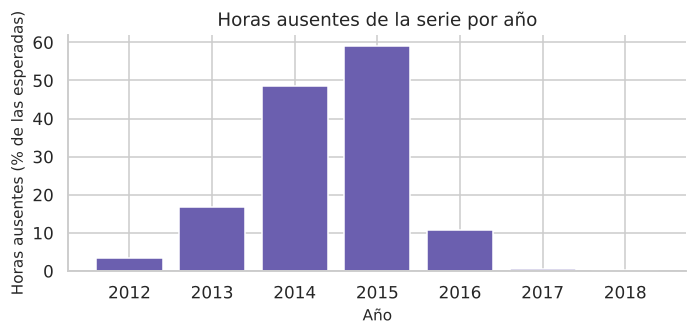

**Lectura.** Faltan 22,8 % de las horas del periodo. El año con mayor ausencia es 2015 (59,0 %), y el 68,4 % de las horas ausentes pertenece a bloques de más de un día; el más largo dura 308 días. Estas horas no son celdas vacías sino filas inexistentes, por lo que **no se imputan**: no hay variable objetivo que reconstruir y hacerlo inventaría tráfico. La consecuencia es metodológica: no deben crearse variables de rezago ingenuas y el modelo debe describirse como un modelo de calendario y clima, no como un pronóstico de serie continua.

In [9]:
# Vista de análisis: sin duplicados exactos, una fila por hora (la primera), valores imposibles → NaN
df_eda = (df.drop_duplicates()
            .sort_values("date_time", kind="stable")
            .drop_duplicates("date_time", keep="first")
            .reset_index(drop=True))
df_eda.loc[df_eda["temp"] <= 0, "temp"] = np.nan
df_eda.loc[df_eda["rain_1h"] > 100, "rain_1h"] = np.nan

rango_completo = pd.date_range(df_eda["date_time"].min(), df_eda["date_time"].max(), freq="h")
ausentes = rango_completo.difference(df_eda["date_time"])

esperadas = pd.Series(rango_completo.year).value_counts().sort_index()
faltan = pd.Series(ausentes.year).value_counts().reindex(esperadas.index, fill_value=0)
cobertura = pd.DataFrame({"horas esperadas": esperadas, "horas ausentes": faltan})
cobertura["% ausente"] = cobertura["horas ausentes"] / cobertura["horas esperadas"] * 100
display(cobertura)

s = pd.Series(ausentes)
bloque = (s.diff() != pd.Timedelta(hours=1)).cumsum()
bloques = s.groupby(bloque).agg(inicio="min", fin="max", horas="count").sort_values("horas", ascending=False)
bloques["días"] = bloques["horas"] / 24
print(f"Horas ausentes: {fmt(len(ausentes),0)} de {fmt(len(rango_completo),0)} esperadas "
      f"({fmt(len(ausentes)/len(rango_completo)*100,1)} %) en {len(bloques)} bloques.")
display(bloques.head(5))

pct_largos = bloques.loc[bloques["horas"] > 24, "horas"].sum() / bloques["horas"].sum() * 100
anio_max = cobertura["% ausente"].idxmax()

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(cobertura.index.astype(str), cobertura["% ausente"], color=COLOR)
ax.set_title("Horas ausentes de la serie por año")
ax.set_xlabel("Año"); ax.set_ylabel("Horas ausentes (% de las esperadas)")
plt.tight_layout(); plt.show()

nota(f"**Lectura.** Faltan {fmt(len(ausentes)/len(rango_completo)*100,1)} % de las horas del periodo. "
     f"El año con mayor ausencia es {anio_max} ({fmt(cobertura.loc[anio_max,'% ausente'],1)} %), y el {fmt(pct_largos,1)} % de las horas ausentes "
     f"pertenece a bloques de más de un día; el más largo dura {fmt(bloques['días'].iloc[0],0)} días. "
     "Estas horas no son celdas vacías sino filas inexistentes, por lo que **no se imputan**: no hay variable objetivo que reconstruir "
     "y hacerlo inventaría tráfico. La consecuencia es metodológica: no deben crearse variables de rezago ingenuas y el modelo "
     "debe describirse como un modelo de calendario y clima, no como un pronóstico de serie continua.")

## 3.5 Consistencia de las categorías

In [10]:
wd = df_eda["weather_description"]
print("weather_description:", wd.nunique(), "valores | tras normalizar mayúsculas/espacios:", wd.str.lower().str.strip().nunique())
print("weather_main:", df_eda["weather_main"].nunique(), "valores | tras normalizar:", df_eda["weather_main"].str.lower().str.strip().nunique())
print("holiday:", df_eda["holiday"].nunique(), "valores")

rel = (df_eda.groupby("weather_description")["weather_main"].nunique())
print("Descripciones que aparecen bajo más de un weather_main:", int((rel > 1).sum()))
display(df_eda["holiday"].value_counts().to_frame("frecuencia"))

weather_description: 35 valores | tras normalizar mayúsculas/espacios: 34
weather_main: 11 valores | tras normalizar: 11
holiday: 12 valores
Descripciones que aparecen bajo más de un weather_main: 0


,frecuencia
holiday,
None,40522
Columbus Day,5
Veterans Day,5
Thanksgiving Day,5
Christmas Day,5
New Years Day,5
Washingtons Birthday,5
Memorial Day,5
Independence Day,5


## 3.6 Valores atípicos (regla IQR y Z-score)

Se aplican las dos reglas a las variables cuantitativas. La regla IQR marca como atípico todo valor fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]; la regla Z-score, todo valor con |z| > 3. La regla del IQR sigue a Tukey (1977).

In [11]:
df_eda["temp_c"] = df_eda["temp"] - 273.15
NUM = ["temp_c", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]

def resumen_outliers(s):
    x = s.dropna()
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = int(((x < li) | (x > ls)).sum())
    n_z = int((np.abs(stats.zscore(x)) > 3).sum())
    return {"Q1": q1, "Q3": q3, "IQR": iqr, "límite inf.": li, "límite sup.": ls,
            "n outliers IQR": n_iqr, "% IQR": n_iqr / len(x) * 100,
            "n outliers Z>3": n_z, "% Z>3": n_z / len(x) * 100,
            "% valores ≠ 0": (x != 0).mean() * 100}

outl = pd.DataFrame({v: resumen_outliers(df_eda[v]) for v in NUM}).T
display(outl)

iqr0 = [v for v in ["rain_1h", "snow_1h"] if outl.loc[v, "IQR"] == 0]
txt = ""
if iqr0:
    txt += (f"En {', '.join('`'+v+'`' for v in iqr0)} el IQR es 0 porque la gran mayoría de las horas no tiene precipitación; "
            "por eso la regla IQR marca como «atípica» **toda** hora con lluvia o nieve. Esos valores no son errores: son el evento real "
            "que interesa modelar. Se distingue entre extremos reales (se conservan, con transformación logarítmica o recorte por percentiles si es necesario) "
            "y los errores de captura de la sección 3.2 (ya aislados). ")
mayor = outl[["% IQR", "% Z>3"]].drop(index=["rain_1h", "snow_1h"]).stack().idxmax()
p_max = outl.loc[mayor[0], mayor[1]]
if p_max == 0:
    txt += "En `temp_c`, `clouds_all` y `traffic_volume` ninguna de las dos reglas marca valores atípicos: no hay nada que recortar ni eliminar en ellas."
else:
    txt += (f"Entre las demás variables, la mayor proporción de atípicos es {fmt(p_max,2)} % "
            f"({mayor[1]} en `{mayor[0]}`); las dos reglas no siempre coinciden, y la decisión de tratamiento se toma en la Fase 2.")
nota("**Lectura.** " + txt)

,Q1,Q3,IQR,límite inf.,límite sup.,n outliers IQR,% IQR,n outliers Z>3,% Z>3,% valores ≠ 0
temp_c,"-1,30","19,13","20,43","-31,94","49,77","0,00","0,00","0,00","0,00","99,91"
rain_1h,"0,00","0,00","0,00","0,00","0,00","2.053,00","5,06","302,00","0,74","5,06"
snow_1h,"0,00","0,00","0,00","0,00","0,00","31,00","0,08","31,00","0,08","0,08"
clouds_all,"1,00","90,00","89,00","-132,50","223,50","0,00","0,00","0,00","0,00","95,16"
traffic_volume,"1.248,50","4.952,00","3.703,50","-4.306,75","10.507,25","0,00","0,00","0,00","0,00","100,00"


**Lectura.** En `rain_1h`, `snow_1h` el IQR es 0 porque la gran mayoría de las horas no tiene precipitación; por eso la regla IQR marca como «atípica» **toda** hora con lluvia o nieve. Esos valores no son errores: son el evento real que interesa modelar. Se distingue entre extremos reales (se conservan, con transformación logarítmica o recorte por percentiles si es necesario) y los errores de captura de la sección 3.2 (ya aislados). En `temp_c`, `clouds_all` y `traffic_volume` ninguna de las dos reglas marca valores atípicos: no hay nada que recortar ni eliminar en ellas.

---
## Vista de análisis y variables auxiliares

Para el EDA se usa `df_eda`: sin duplicados, **una fila por hora** y con los valores imposibles convertidos en faltantes. Se añaden variables **auxiliares de exploración** derivadas del calendario; su tratamiento formal (codificación, escalamiento y partición) se hace en la Fase 2.

In [12]:
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
dt = df_eda["date_time"].dt
df_eda["hora"] = dt.hour
df_eda["dia_semana"] = dt.dayofweek            # 0 = lunes
df_eda["mes"] = dt.month
df_eda["anio"] = dt.year
df_eda["es_fin_de_semana"] = (df_eda["dia_semana"] >= 5).astype(int)

fechas_festivas = set(df_eda.loc[df_eda["holiday"] != "None", "date_time"].dt.date)
df_eda["es_festivo"] = df_eda["date_time"].dt.date.isin(fechas_festivas).astype(int)

df_eda["franja"] = pd.cut(df_eda["hora"], bins=[-1, 5, 11, 17, 23],
                          labels=["Madrugada (0-5)", "Mañana (6-11)", "Tarde (12-17)", "Noche (18-23)"])
df_eda["estacion"] = df_eda["mes"].map({12: "Invierno", 1: "Invierno", 2: "Invierno",
                                        3: "Primavera", 4: "Primavera", 5: "Primavera",
                                        6: "Verano", 7: "Verano", 8: "Verano",
                                        9: "Otoño", 10: "Otoño", 11: "Otoño"})

# Variable categórica derivada para clasificación (umbrales fijos, justificados en la sección 4.3)
UMBRAL_BAJO, UMBRAL_ALTO = 1500, 4500
df_eda["nivel_trafico"] = pd.cut(df_eda["traffic_volume"], bins=[-np.inf, UMBRAL_BAJO, UMBRAL_ALTO, np.inf],
                                 labels=["bajo", "medio", "alto"], right=False)

# Agrupa categorías de clima con menos de 50 horas (se usa en gráficos y pruebas χ²)
conteo_w = df_eda["weather_main"].value_counts()
df_eda["weather_grupo"] = df_eda["weather_main"].where(df_eda["weather_main"].map(conteo_w) >= 50, "Otros")

print(f"Vista de análisis: {fmt(len(df_eda),0)} horas × {df_eda.shape[1]} columnas")
print(f"Horas marcadas como festivas (día completo): {fmt(df_eda['es_festivo'].sum(),0)}")

Vista de análisis: 40.575 horas × 20 columnas
Horas marcadas como festivas (día completo): 1.203


---
# 4. Análisis univariado

## 4.1 Variables cuantitativas: tendencia central, dispersión, asimetría y curtosis

In [13]:
desc = df_eda[NUM].agg(["count", "mean", "median", "std", "min", "max"]).T
desc["Q1"] = df_eda[NUM].quantile(.25)
desc["Q3"] = df_eda[NUM].quantile(.75)
desc["asimetría"] = df_eda[NUM].skew()
desc["curtosis (exceso)"] = df_eda[NUM].kurt()
desc["moda"] = [df_eda[c].mode().iloc[0] for c in NUM]
desc = desc[["count", "mean", "median", "moda", "std", "min", "Q1", "Q3", "max", "asimetría", "curtosis (exceso)"]]
display(desc)

,count,mean,median,moda,std,min,Q1,Q3,max,asimetría,curtosis (exceso)
temp_c,"40.565,00","8,24","9,72","1,00","13,09","-29,76","-1,30","19,13","36,92","-0,38","-0,69"
rain_1h,"40.574,00","0,08","0,00","0,00","0,77","0,00","0,00","0,00","55,63","28,64","1.321,73"
snow_1h,"40.575,00","0,00","0,00","0,00","0,01","0,00","0,00","0,00","0,51","65,91","4.968,37"
clouds_all,"40.575,00","44,20","40,00","1,00","38,68","0,00","1,00","90,00","100,00","0,03","-1,76"
traffic_volume,"40.575,00","3.290,65","3.427,00","356,00","1.984,77","0,00","1.248,50","4.952,00","7.280,00","-0,11","-1,30"


In [14]:
def lectura_forma(nombre, skew, kurt):
    if abs(skew) < 0.5: a = "aproximadamente simétrica"
    elif abs(skew) < 1: a = "con asimetría moderada " + ("a la derecha" if skew > 0 else "a la izquierda")
    else: a = "fuertemente asimétrica " + ("a la derecha" if skew > 0 else "a la izquierda")
    if kurt > 1: k = "colas más pesadas que la normal (leptocúrtica)"
    elif kurt < -1: k = "más aplanada que la normal (platicúrtica)"
    else: k = "curtosis cercana a la normal"
    return f"- **{nombre}**: {a} (asimetría = {fmt(skew)}) y {k} (exceso = {fmt(kurt)})."

lineas = [lectura_forma(c, desc.loc[c, "asimetría"], desc.loc[c, "curtosis (exceso)"]) for c in NUM]
k_tv = desc.loc["traffic_volume", "curtosis (exceso)"]
lineas.append(f"- En `traffic_volume`, media ({fmt(desc.loc['traffic_volume','mean'],0)}) y mediana ({fmt(desc.loc['traffic_volume','median'],0)}) están cerca, pero "
              + ("la curtosis negativa indica una distribución más aplanada que la campana, compatible con varios picos (ver histograma): "
                 "la media y la mediana por sí solas no describen bien una variable con regímenes distintos de flujo."
                 if k_tv < -1 else "la forma del histograma permite verificar si existe más de un régimen de flujo."))
nota("**Lectura de resultados**\n\n" + "\n".join(lineas))

**Lectura de resultados**

- **temp_c**: aproximadamente simétrica (asimetría = -0,38) y curtosis cercana a la normal (exceso = -0,69).
- **rain_1h**: fuertemente asimétrica a la derecha (asimetría = 28,64) y colas más pesadas que la normal (leptocúrtica) (exceso = 1.321,73).
- **snow_1h**: fuertemente asimétrica a la derecha (asimetría = 65,91) y colas más pesadas que la normal (leptocúrtica) (exceso = 4.968,37).
- **clouds_all**: aproximadamente simétrica (asimetría = 0,03) y más aplanada que la normal (platicúrtica) (exceso = -1,76).
- **traffic_volume**: aproximadamente simétrica (asimetría = -0,11) y más aplanada que la normal (platicúrtica) (exceso = -1,30).
- En `traffic_volume`, media (3.291) y mediana (3.427) están cerca, pero la curtosis negativa indica una distribución más aplanada que la campana, compatible con varios picos (ver histograma): la media y la mediana por sí solas no describen bien una variable con regímenes distintos de flujo.

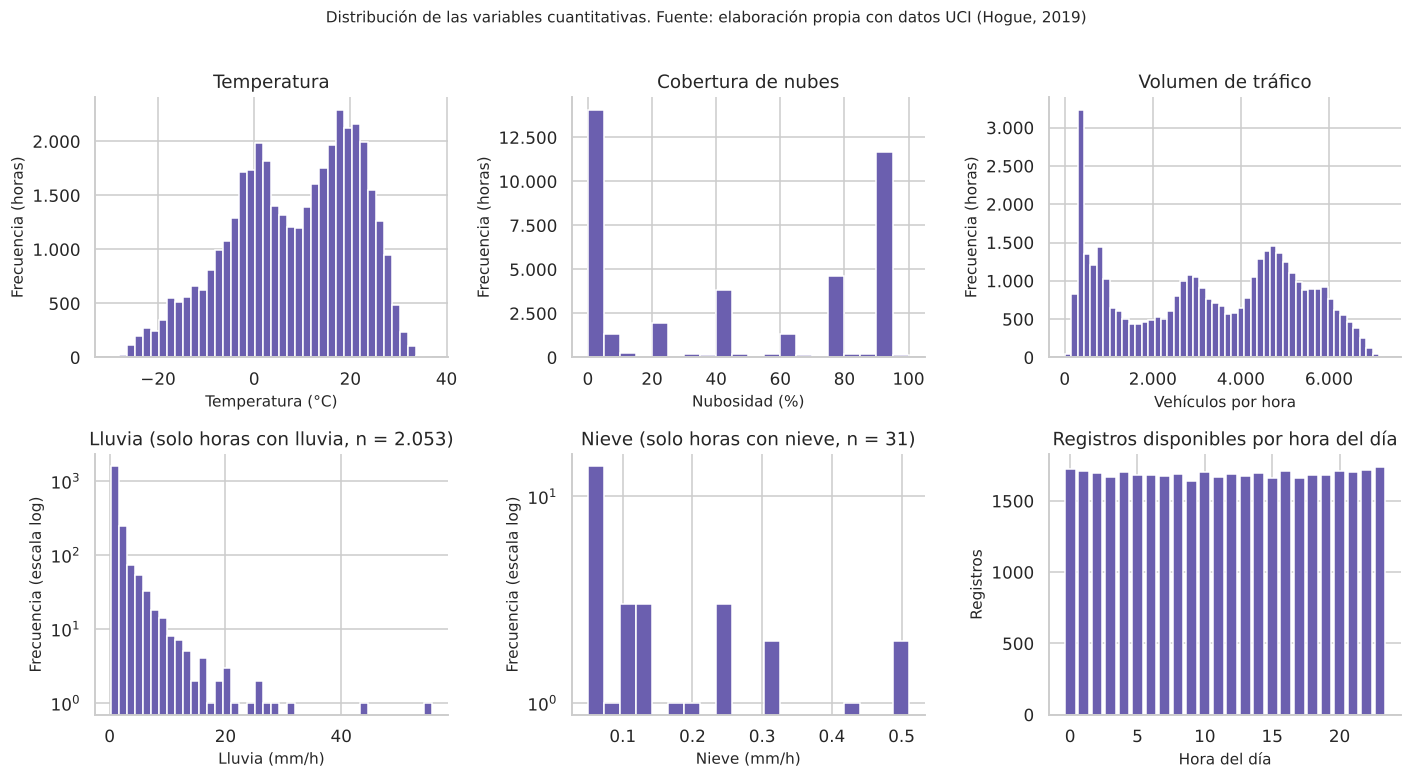

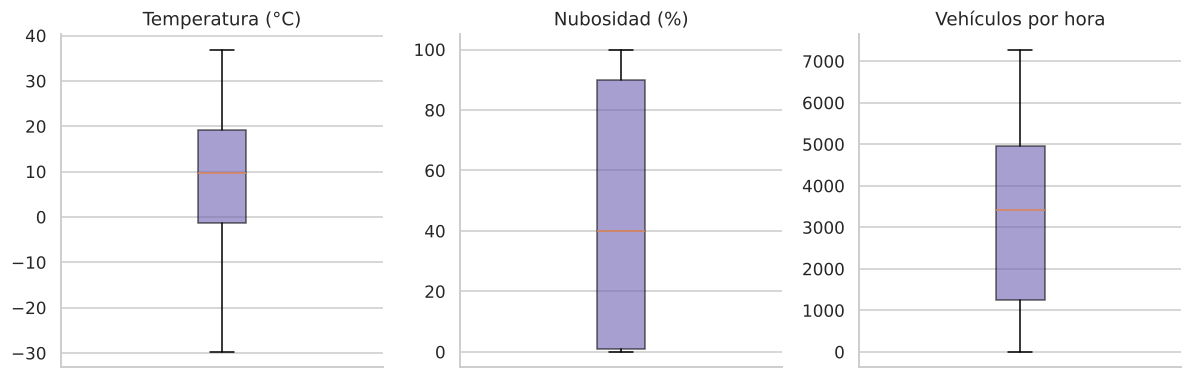

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
ax = axes[0, 0]; ax.hist(df_eda["temp_c"].dropna(), bins=40, color=COLOR); ax.set_title("Temperatura"); ax.set_xlabel("Temperatura (°C)"); ax.set_ylabel("Frecuencia (horas)"); miles(ax)
ax = axes[0, 1]; ax.hist(df_eda["clouds_all"], bins=20, color=COLOR); ax.set_title("Cobertura de nubes"); ax.set_xlabel("Nubosidad (%)"); ax.set_ylabel("Frecuencia (horas)"); miles(ax)
ax = axes[0, 2]; ax.hist(df_eda["traffic_volume"], bins=50, color=COLOR); ax.set_title("Volumen de tráfico"); ax.set_xlabel("Vehículos por hora"); ax.set_ylabel("Frecuencia (horas)"); miles(ax); miles(ax, "x")
ax = axes[1, 0]; x = df_eda.loc[df_eda["rain_1h"] > 0, "rain_1h"]; ax.hist(x, bins=40, color=COLOR); ax.set_yscale("log"); ax.set_title(f"Lluvia (solo horas con lluvia, n = {fmt(len(x),0)})"); ax.set_xlabel("Lluvia (mm/h)"); ax.set_ylabel("Frecuencia (escala log)")
ax = axes[1, 1]; x = df_eda.loc[df_eda["snow_1h"] > 0, "snow_1h"]; ax.hist(x, bins=20, color=COLOR); ax.set_yscale("log"); ax.set_title(f"Nieve (solo horas con nieve, n = {fmt(len(x),0)})"); ax.set_xlabel("Nieve (mm/h)"); ax.set_ylabel("Frecuencia (escala log)")
ax = axes[1, 2]; ax.bar(range(24), df_eda["hora"].value_counts().sort_index(), color=COLOR); ax.set_title("Registros disponibles por hora del día"); ax.set_xlabel("Hora del día"); ax.set_ylabel("Registros")
plt.suptitle("Distribución de las variables cuantitativas. Fuente: elaboración propia con datos UCI (Hogue, 2019)", y=1.01, fontsize=10)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (c, t) in zip(axes, [("temp_c", "Temperatura (°C)"), ("clouds_all", "Nubosidad (%)"), ("traffic_volume", "Vehículos por hora")]):
    ax.boxplot(df_eda[c].dropna(), patch_artist=True, boxprops=dict(facecolor=COLOR, alpha=.6), flierprops=dict(markersize=2, alpha=.3))
    ax.set_title(t); ax.set_xticks([])
plt.tight_layout(); plt.show()

## 4.2 Variables cualitativas: tablas de frecuencias

holiday


,frecuencia,%,% acumulado
holiday,,,
None,40522,"99,87","99,87"
Columbus Day,5,"0,01","99,88"
Veterans Day,5,"0,01","99,89"
Thanksgiving Day,5,"0,01","99,91"
Christmas Day,5,"0,01","99,92"
New Years Day,5,"0,01","99,93"
Washingtons Birthday,5,"0,01","99,94"
Memorial Day,5,"0,01","99,96"
Independence Day,5,"0,01","99,97"


weather_main


,frecuencia,%,% acumulado
weather_main,,,
Clouds,15123,"37,27","37,27"
Clear,13366,"32,94","70,21"
Rain,4769,"11,75","81,97"
Mist,3069,"7,56","89,53"
Snow,2297,"5,66","95,19"
Haze,766,"1,89","97,08"
Drizzle,515,"1,27","98,35"
Thunderstorm,453,"1,12","99,47"
Fog,201,"0,50","99,96"


weather_description (10 más frecuentes)


,frecuencia,%,% acumulado
weather_description,,,
sky is clear,11642,"28,69","28,69"
overcast clouds,5072,"12,50","41,19"
broken clouds,4650,"11,46","52,65"
scattered clouds,3451,"8,51","61,16"
mist,3069,"7,56","68,72"
light rain,2831,"6,98","75,70"
few clouds,1950,"4,81","80,51"
Sky is Clear,1724,"4,25","84,75"
light snow,1588,"3,91","88,67"


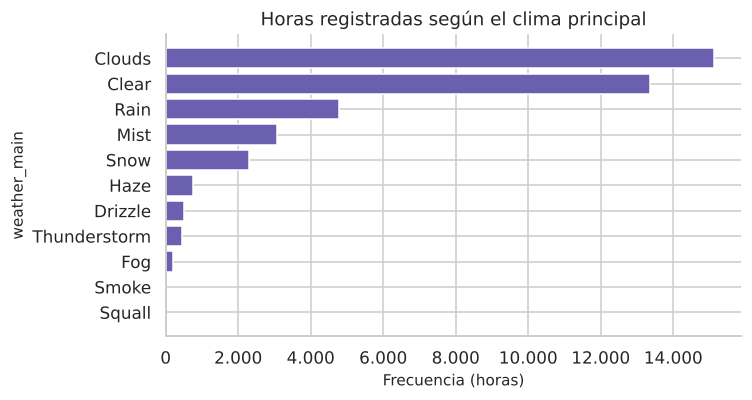

**Lectura.** El clima más frecuente es `Clouds` (37,3 % de las horas). Los festivos son muy escasos: hay 53 fechas festivas distintas en todo el periodo. Las categorías de clima poco frecuentes darán celdas con pocas observaciones; por eso se agrupan en «Otros» (menos de 50 horas) para las pruebas de independencia y los gráficos.

In [16]:
def tabla_frec(s, top=None):
    vc = s.value_counts()
    t = pd.DataFrame({"frecuencia": vc, "%": vc / vc.sum() * 100})
    t["% acumulado"] = t["%"].cumsum()
    return t.head(top) if top else t

print("holiday"); display(tabla_frec(df_eda["holiday"]))
print("weather_main"); display(tabla_frec(df_eda["weather_main"]))
print("weather_description (10 más frecuentes)"); display(tabla_frec(df_eda["weather_description"], 10))

fig, ax = plt.subplots(figsize=(7, 3.8))
t = tabla_frec(df_eda["weather_main"])["frecuencia"].sort_values()
ax.barh(t.index, t.values, color=COLOR)
ax.set_title("Horas registradas según el clima principal"); ax.set_xlabel("Frecuencia (horas)"); ax.set_ylabel("weather_main")
miles(ax, "x"); plt.tight_layout(); plt.show()

dom = tabla_frec(df_eda["weather_main"]).iloc[0]
n_fest = df_eda.loc[df_eda["holiday"] != "None", "date_time"].dt.date.nunique()
nota(f"**Lectura.** El clima más frecuente es `{tabla_frec(df_eda['weather_main']).index[0]}` ({fmt(dom['%'],1)} % de las horas). "
     f"Los festivos son muy escasos: hay {n_fest} fechas festivas distintas en todo el periodo. Las categorías de clima poco frecuentes "
     "darán celdas con pocas observaciones; por eso se agrupan en «Otros» (menos de 50 horas) para las pruebas de independencia y los gráficos.")

## 4.3 Variable categórica derivada para clasificación: `nivel_trafico`

Se define con **umbrales fijos** sobre `traffic_volume`: **Bajo** (< 1.500 vehículos/h), **Medio** (1.500 a < 4.500) y **Alto** (≥ 4.500). Los umbrales se fijan *a priori* (no se recalculan con cuantiles de cada partición), de modo que la definición de la etiqueta no cambia entre entrenamiento, validación y prueba. Como se aprecia en el histograma siguiente, el corte de 1.500 queda en el valle entre la concentración de madrugada y la intermedia, y el de 4.500 al comienzo de la concentración de mayor demanda. Se trata de una decisión de diseño tomada observando la distribución completa del volumen, lo que se declara como limitación (sección 6).

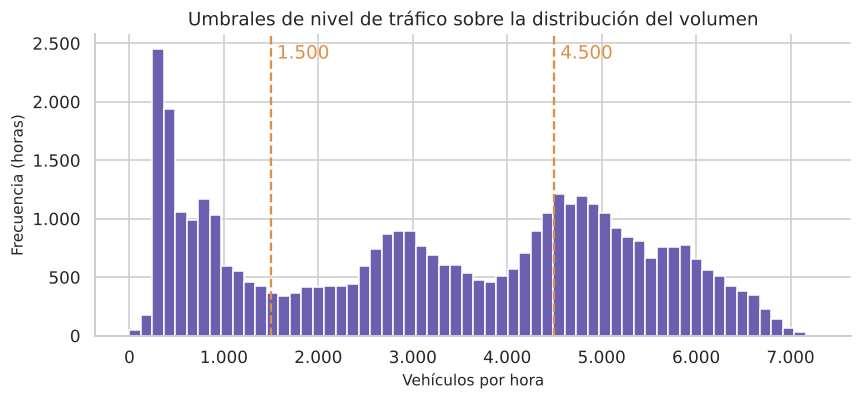

,frecuencia,%,% acumulado
nivel_trafico,,,
bajo,11030,"27,18","100,00"
medio,15030,"37,04","37,04"
alto,14515,"35,77","72,82"


**Lectura.** Distribución de clases: 27,2 % Bajo, 37,0 % Medio y 35,8 % Alto. La razón entre la clase mayoritaria y la minoritaria es 1,36; no constituye un desbalance severo, por lo que bastará con partición estratificada y, si hiciera falta, `class_weight`, sin recurrir a SMOTE.

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(df_eda["traffic_volume"], bins=60, color=COLOR)
for u, t in [(UMBRAL_BAJO, "1.500"), (UMBRAL_ALTO, "4.500")]:
    ax.axvline(u, color=COLOR2, ls="--"); ax.text(u, ax.get_ylim()[1] * .92, f" {t}", color=COLOR2)
ax.set_title("Umbrales de nivel de tráfico sobre la distribución del volumen")
ax.set_xlabel("Vehículos por hora"); ax.set_ylabel("Frecuencia (horas)")
miles(ax); miles(ax, "x"); plt.tight_layout(); plt.show()

dist = tabla_frec(df_eda["nivel_trafico"]).loc[["bajo", "medio", "alto"]]
display(dist)
ratio = dist["frecuencia"].max() / dist["frecuencia"].min()
nota(f"**Lectura.** Distribución de clases: {fmt(dist.loc['bajo','%'],1)} % Bajo, {fmt(dist.loc['medio','%'],1)} % Medio y {fmt(dist.loc['alto','%'],1)} % Alto. "
     f"La razón entre la clase mayoritaria y la minoritaria es {fmt(ratio,2)}; "
     + ("no constituye un desbalance severo, por lo que bastará con partición estratificada y, si hiciera falta, `class_weight`, sin recurrir a SMOTE."
        if ratio < 3 else "es un desbalance relevante y se evaluará `class_weight` o SMOTE en la Fase 2."))

---
# 5. Análisis bivariado y multivariado

## 5.1 Matriz de correlación (Pearson y Spearman)

Se usan ambas porque la relación entre la hora del día y el volumen **no es monótona** (sube en las horas pico y baja en la madrugada); Pearson solo mide relación lineal y Spearman solo monotónica, así que una correlación baja no implica ausencia de relación.

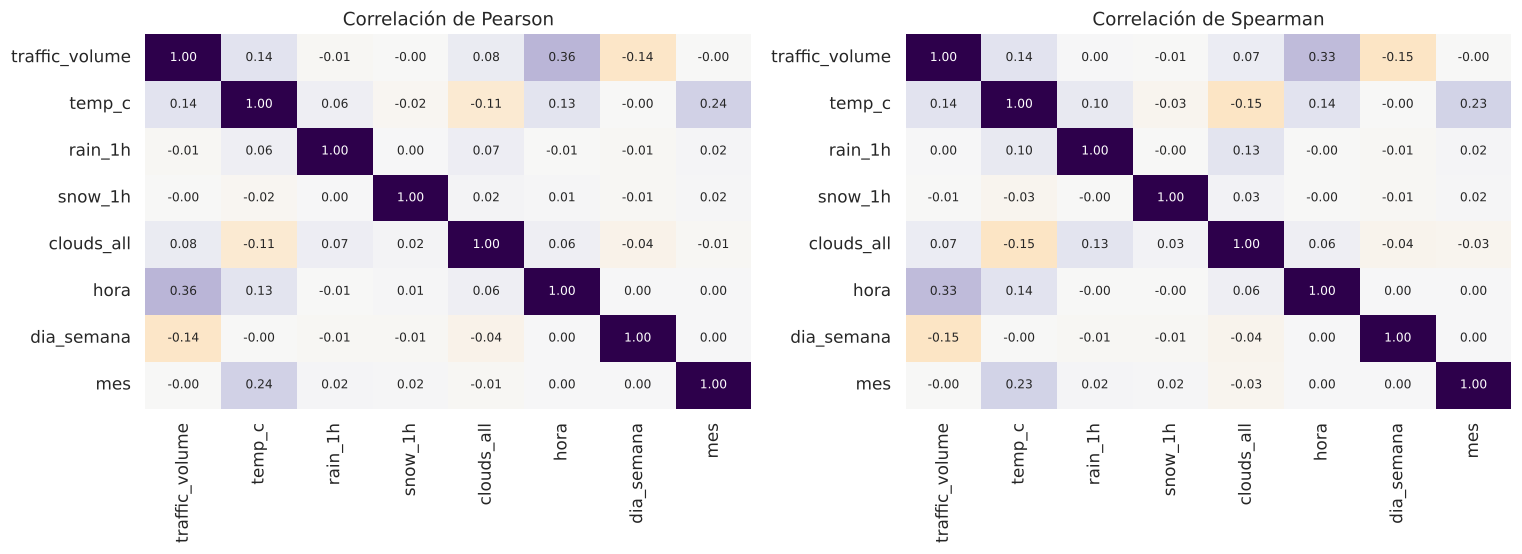

,Pearson,Spearman,|Spearman|
hora,"0,36","0,33","0,33"
dia_semana,"-0,14","-0,15","0,15"
temp_c,"0,14","0,14","0,14"
clouds_all,"0,08","0,07","0,07"
snow_1h,"-0,00","-0,01","0,01"
rain_1h,"-0,01","0,00","0,00"
mes,"-0,00","-0,00","0,00"


**Lectura.** La variable numérica con mayor correlación (Spearman) con el volumen es `hora` (0,33). Entre las variables meteorológicas, la mayor |Spearman| es 0,14. Estas son bajas, lo que sugiere que el clima, por sí solo, no es el motor principal de la demanda. La correlación lineal de `hora` es 0,36: una relación no monótona (picos y valles) queda subestimada por Pearson y Spearman, por lo que se examina con el perfil horario de la sección 5.3.

In [18]:
VARS_CORR = ["traffic_volume", "temp_c", "rain_1h", "snow_1h", "clouds_all", "hora", "dia_semana", "mes"]
pear = df_eda[VARS_CORR].corr(method="pearson")
spea = df_eda[VARS_CORR].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, m, t in zip(axes, [pear, spea], ["Pearson", "Spearman"]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="PuOr", center=0, vmin=-1, vmax=1, ax=ax, cbar=False, annot_kws={"size": 8})
    ax.set_title(f"Correlación de {t}")
plt.tight_layout(); plt.show()

cor_obj = pd.DataFrame({"Pearson": pear["traffic_volume"], "Spearman": spea["traffic_volume"]}).drop("traffic_volume")
cor_obj["|Spearman|"] = cor_obj["Spearman"].abs()
display(cor_obj.sort_values("|Spearman|", ascending=False))
top = cor_obj["|Spearman|"].idxmax()
clima_vars = ["temp_c", "rain_1h", "snow_1h", "clouds_all"]
max_clima = cor_obj.loc[clima_vars, "|Spearman|"].max()
txt = (f"La variable numérica con mayor correlación (Spearman) con el volumen es `{top}` ({fmt(cor_obj.loc[top,'Spearman'])}). "
       f"Entre las variables meteorológicas, la mayor |Spearman| es {fmt(max_clima)}. ")
txt += ("Estas son bajas, lo que sugiere que el clima, por sí solo, no es el motor principal de la demanda. " if max_clima < 0.3
        else "Hay una correlación meteorológica apreciable que conviene separar del efecto estacional del calendario. ")
txt += (f"La correlación lineal de `hora` es {fmt(cor_obj.loc['hora','Pearson'])}: una relación no monótona (picos y valles) queda subestimada por Pearson y Spearman, "
        "por lo que se examina con el perfil horario de la sección 5.3.")
nota("**Lectura.** " + txt)

## 5.2 Diagramas de dispersión: variables meteorológicas frente al volumen

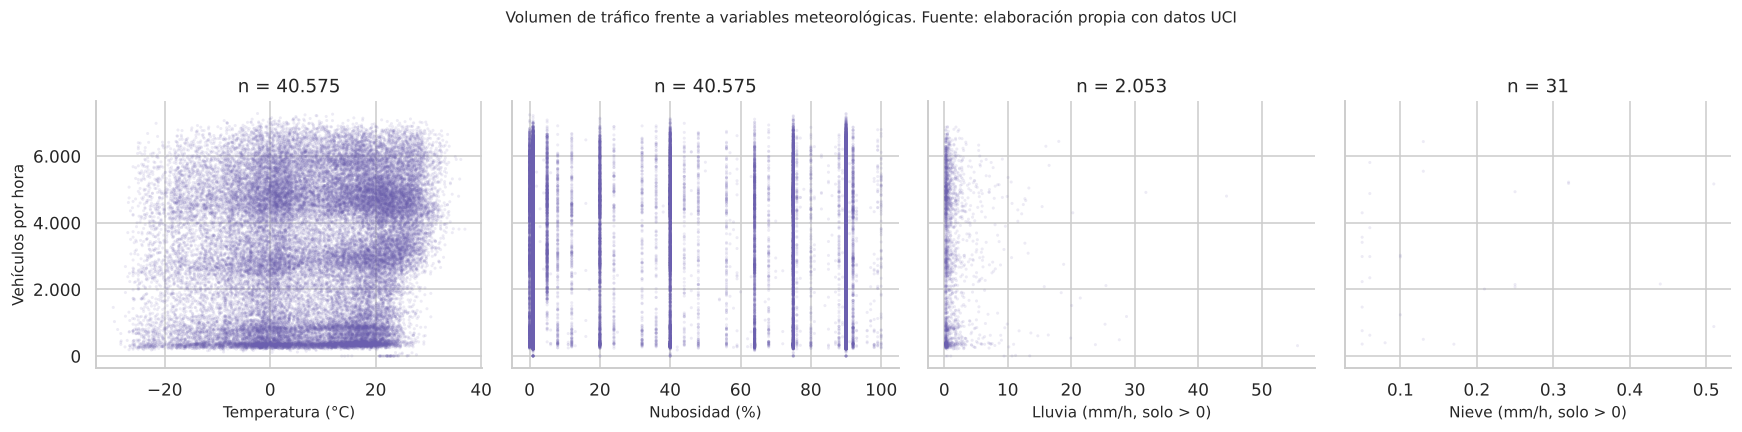

**Lectura.** Cada gráfico muestra la dispersión del volumen frente a una variable meteorológica (Spearman con la temperatura = 0,14). Si las nubes de puntos son anchas y sin tendencia clara, para un mismo valor del clima se observan volúmenes muy distintos, señal de que otro factor (el calendario, sección 5.3) explica esa variación.

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
datos = [("temp_c", "Temperatura (°C)", df_eda), ("clouds_all", "Nubosidad (%)", df_eda),
         ("rain_1h", "Lluvia (mm/h, solo > 0)", df_eda[df_eda["rain_1h"] > 0]),
         ("snow_1h", "Nieve (mm/h, solo > 0)", df_eda[df_eda["snow_1h"] > 0])]
for ax, (c, t, d) in zip(axes, datos):
    ax.scatter(d[c], d["traffic_volume"], s=4, alpha=.12, color=COLOR, edgecolors="none")
    ax.set_xlabel(t); ax.set_title(f"n = {fmt(len(d),0)}")
axes[0].set_ylabel("Vehículos por hora"); miles(axes[0])
plt.suptitle("Volumen de tráfico frente a variables meteorológicas. Fuente: elaboración propia con datos UCI", y=1.03, fontsize=10)
plt.tight_layout(); plt.show()
r_t = df_eda[["temp_c", "traffic_volume"]].corr(method="spearman").iloc[0, 1]
nota(f"**Lectura.** Cada gráfico muestra la dispersión del volumen frente a una variable meteorológica (Spearman con la temperatura = {fmt(r_t)}). "
     "Si las nubes de puntos son anchas y sin tendencia clara, para un mismo valor del clima se observan volúmenes muy distintos, "
     "señal de que otro factor (el calendario, sección 5.3) explica esa variación.")

## 5.3 El calendario: perfil horario, día de la semana, estacionalidad y festivos

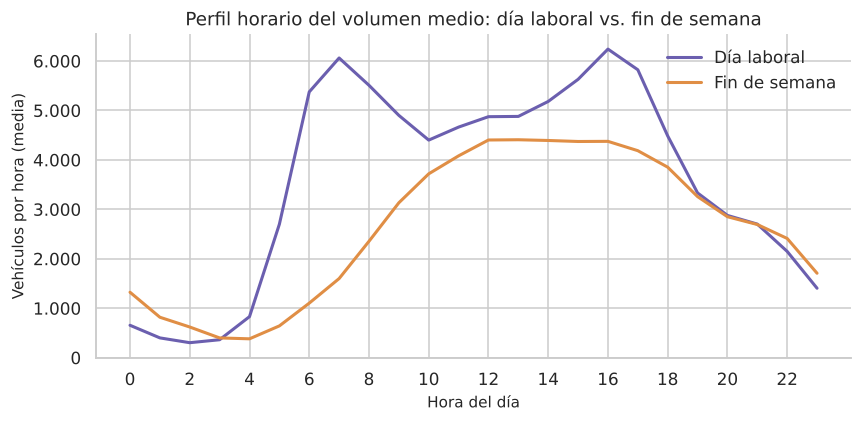

**Lectura.** En días laborales el volumen medio alcanza su máximo a las 16:00 h (6.241 vehículos/h); en fines de semana, a las 13:00 h (4.408). La variación del volumen a lo largo del día (desviación estándar del perfil) es 2.042 en días laborales y 1.486 en fines de semana. Esta interacción hora × tipo de día es la razón por la que la hora y el día de la semana deben modelarse conjuntamente.

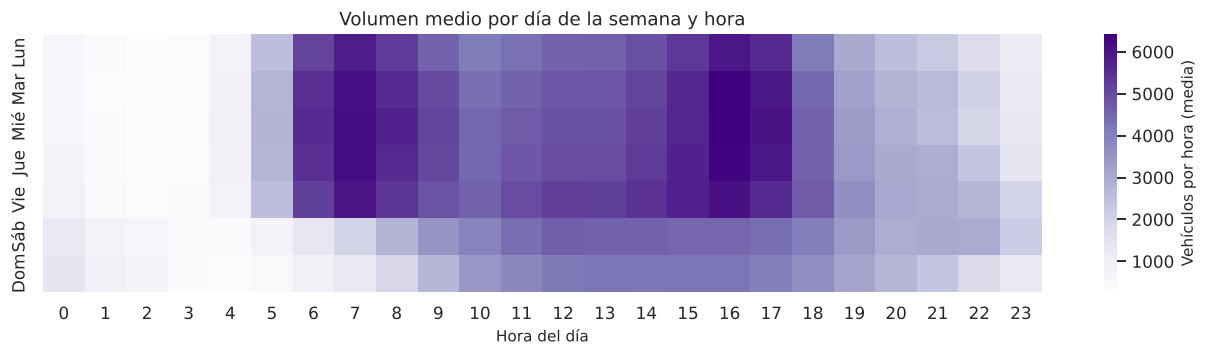

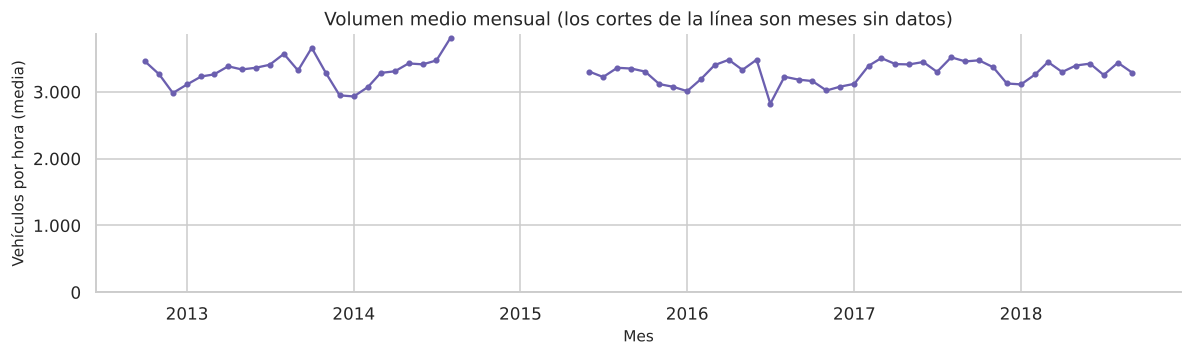

,count,mean,median
Laboral no festivo,27776,"3.600,70","4.286,00"
Laboral festivo,1203,"2.558,74","2.588,00"


**Lectura.** Entre lunes y viernes, un día festivo tiene en promedio 1.042 vehículos/h menos que un día laboral normal (2.559 frente a 3.601), lo que justifica una variable de festivo propagada al día completo.

In [20]:
perfil = df_eda.groupby(["es_fin_de_semana", "hora"])["traffic_volume"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(perfil.index, perfil[0], color=COLOR, lw=2, label="Día laboral")
ax.plot(perfil.index, perfil[1], color=COLOR2, lw=2, label="Fin de semana")
ax.set_title("Perfil horario del volumen medio: día laboral vs. fin de semana")
ax.set_xlabel("Hora del día"); ax.set_ylabel("Vehículos por hora (media)"); ax.set_xticks(range(0, 24, 2))
ax.set_ylim(bottom=0); ax.legend(frameon=False); miles(ax); plt.tight_layout(); plt.show()

hora_pico_lab = perfil[0].idxmax(); hora_pico_fin = perfil[1].idxmax()
nota(f"**Lectura.** En días laborales el volumen medio alcanza su máximo a las {hora_pico_lab}:00 h ({fmt(perfil[0].max(),0)} vehículos/h); "
     f"en fines de semana, a las {hora_pico_fin}:00 h ({fmt(perfil[1].max(),0)}). "
     f"La variación del volumen a lo largo del día (desviación estándar del perfil) es {fmt(perfil[0].std(),0)} en días laborales y {fmt(perfil[1].std(),0)} en fines de semana. "
     "Esta interacción hora × tipo de día es la razón por la que la hora y el día de la semana deben modelarse conjuntamente.")

piv = df_eda.pivot_table(index="dia_semana", columns="hora", values="traffic_volume", aggfunc="mean")
piv.index = DIAS
fig, ax = plt.subplots(figsize=(12, 3.4))
sns.heatmap(piv, cmap="Purples", ax=ax, cbar_kws={"label": "Vehículos por hora (media)"})
ax.set_title("Volumen medio por día de la semana y hora"); ax.set_xlabel("Hora del día"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

mensual = df_eda.set_index("date_time")["traffic_volume"].resample("MS").mean()
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(mensual.index, mensual.values, color=COLOR, lw=1.5, marker="o", ms=3)
ax.set_title("Volumen medio mensual (los cortes de la línea son meses sin datos)")
ax.set_xlabel("Mes"); ax.set_ylabel("Vehículos por hora (media)"); ax.set_ylim(bottom=0); miles(ax)
plt.tight_layout(); plt.show()

lab = df_eda[df_eda["dia_semana"] < 5]
fest = lab.groupby("es_festivo")["traffic_volume"].agg(["count", "mean", "median"])
fest.index = ["Laboral no festivo", "Laboral festivo"][: len(fest)]
display(fest)
if len(fest) == 2:
    dif = fest.loc["Laboral festivo", "mean"] - fest.loc["Laboral no festivo", "mean"]
    nota(f"**Lectura.** Entre lunes y viernes, un día festivo tiene en promedio {fmt(abs(dif),0)} vehículos/h {'menos' if dif < 0 else 'más'} que un día laboral normal "
         f"({fmt(fest.loc['Laboral festivo','mean'],0)} frente a {fmt(fest.loc['Laboral no festivo','mean'],0)}), "
         "lo que justifica una variable de festivo propagada al día completo.")

## 5.4 Fuerza de asociación entre factores categóricos y el volumen (razón de correlación η² y Kruskal-Wallis)

Se usa la razón de correlación η² (parte de la varianza del volumen que explica cada factor) y la prueba de Kruskal y Wallis (1952). Los factores de calendario se solapan, por lo que los η² no son aditivos.

,η²,H (Kruskal-Wallis),gl,valor p,ε² (Kruskal)
factor,,,,,
hora,"0,782","31.069,08",23,"< 0,001","0,766"
dia_semana,"0,051","2.282,57",6,"< 0,001","0,056"
es_fin_de_semana,"0,045","2.016,73",1,"< 0,001","0,050"
weather_grupo,"0,021","782,88",9,"< 0,001","0,019"
es_festivo,"0,004","175,11",1,"< 0,001","0,004"
mes,"0,004","187,91",11,"< 0,001","0,004"
anio,"0,001","45,38",6,"< 0,001","0,001"


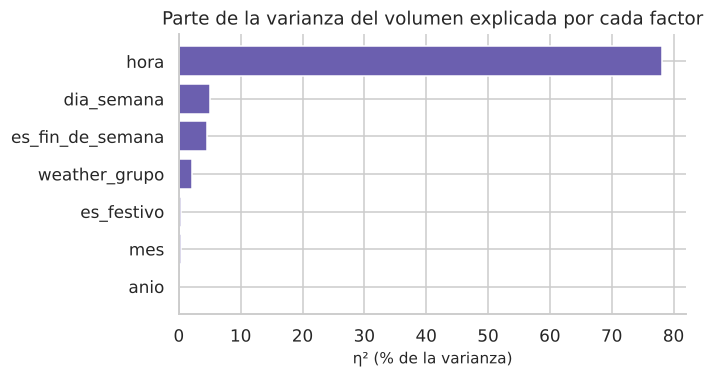

**Lectura.** El factor que más varianza del volumen explica por sí solo es `hora` (η² = 78,2 %), seguido de `dia_semana` (5,1 %). El tipo de clima (`weather_grupo`) explica 2,1 %. Con tantas observaciones, casi cualquier diferencia resulta «significativa» (valor p muy pequeño); por eso se reporta el tamaño del efecto (η², ε²) y no solo el valor p. Esto indica que el calendario domina sobre el clima como determinante del volumen.

In [21]:
def eta2(df_, cat, y="traffic_volume"):
    g = df_.groupby(cat, observed=True)[y]
    ss_between = (g.count() * (g.mean() - df_[y].mean()) ** 2).sum()
    ss_total = ((df_[y] - df_[y].mean()) ** 2).sum()
    return ss_between / ss_total

def kruskal(df_, cat, y="traffic_volume"):
    grupos = [g[y].values for _, g in df_.groupby(cat, observed=True) if len(g) > 1]
    H, p = stats.kruskal(*grupos)
    k, n = len(grupos), len(df_)
    return H, p, (H - k + 1) / (n - k), k - 1

factores = ["hora", "dia_semana", "mes", "anio", "es_festivo", "es_fin_de_semana", "weather_grupo"]
res = []
for f in factores:
    H, p, e, gl = kruskal(df_eda, f)
    res.append({"factor": f, "η²": eta2(df_eda, f), "H (Kruskal-Wallis)": H, "gl": gl, "valor p": fmt_p(p), "ε² (Kruskal)": e})
asoc = pd.DataFrame(res).set_index("factor").sort_values("η²", ascending=False)
display(asoc.style.format({"η²": lambda v: fmt(v, 3), "H (Kruskal-Wallis)": lambda v: fmt(v, 2), "ε² (Kruskal)": lambda v: fmt(v, 3)}))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
a = asoc["η²"].sort_values()
ax.barh(a.index, a.values * 100, color=COLOR)
ax.set_title("Parte de la varianza del volumen explicada por cada factor")
ax.set_xlabel("η² (% de la varianza)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

f1 = asoc.index[0]; f2 = asoc.index[1]
clima = asoc.loc["weather_grupo", "η²"] * 100
nota(f"**Lectura.** El factor que más varianza del volumen explica por sí solo es `{f1}` (η² = {fmt(asoc.iloc[0]['η²']*100,1)} %), seguido de `{f2}` "
     f"({fmt(asoc.iloc[1]['η²']*100,1)} %). El tipo de clima (`weather_grupo`) explica {fmt(clima,1)} %. "
     "Con tantas observaciones, casi cualquier diferencia resulta «significativa» (valor p muy pequeño); por eso se reporta el tamaño del efecto (η², ε²) y no solo el valor p. "
     + ("Esto indica que el calendario domina sobre el clima como determinante del volumen." if max(asoc.loc[["hora","dia_semana","mes","es_fin_de_semana","es_festivo"],"η²"]) > asoc.loc["weather_grupo","η²"]
       else "En este dataset el clima pesa tanto o más que el calendario."))

## 5.5 Pruebas de independencia χ² (variables cualitativas)

Se contrasta, para cada par, **H₀: las variables son independientes** frente a H₁: existe asociación. Como con decenas de miles de filas el valor p es casi siempre diminuto, se reporta además la **V de Cramér** (0 = sin asociación, 1 = asociación perfecta) y la proporción de celdas con frecuencia esperada < 5 (condición de validez de la prueba; Cochran, 1954, recomienda que no supere el 20 %). La intensidad se clasifica con *w* = *V*·√*k* (*k* = menor número de filas o columnas menos 1) y los umbrales de Cohen (1988): < 0,10 muy débil; 0,10 a 0,29 pequeña; 0,30 a 0,49 mediana; ≥ 0,50 grande. La *V* de Cramér es la propuesta de Cramér (1946).

In [22]:
def chi2_cramer(a, b):
    tabla = pd.crosstab(a, b)
    chi2, p, gl, esp = stats.chi2_contingency(tabla)
    n = tabla.values.sum(); k = min(tabla.shape) - 1
    v = np.sqrt(chi2 / (n * k))
    return {"χ²": chi2, "gl": gl, "valor p": fmt_p(p), "V de Cramér": v, "k": k,
            "% celdas esperadas < 5": (esp < 5).mean() * 100,
            "Decisión (α = 0,05)": "Se rechaza H₀" if p < 0.05 else "No se rechaza H₀"}

pares = [("nivel_trafico", "franja"), ("nivel_trafico", "es_fin_de_semana"), ("nivel_trafico", "es_festivo"),
         ("nivel_trafico", "estacion"), ("nivel_trafico", "weather_grupo"), ("franja", "weather_grupo")]
filas = []
for a, b in pares:
    r = chi2_cramer(df_eda[a], df_eda[b]); r["Par"] = f"{a} × {b}"; filas.append(r)
chi = pd.DataFrame(filas).set_index("Par")

def intensidad(v, k):
    w = v * np.sqrt(k)          # criterio de Cohen ajustado por tamaño de la tabla
    return "muy débil" if w < 0.1 else ("pequeña" if w < 0.3 else ("mediana" if w < 0.5 else "grande"))
chi["Intensidad (Cohen)"] = [intensidad(v, k) for v, k in zip(chi["V de Cramér"], chi["k"])]
chi = chi.drop(columns="k")
display(chi)

fuerte = chi["V de Cramér"].idxmax(); debil = chi["V de Cramér"].idxmin()
nota(f"**Lectura.** La asociación más intensa es `{fuerte}` (V = {fmt(chi.loc[fuerte,'V de Cramér'])}) y la más débil `{debil}` (V = {fmt(chi.loc[debil,'V de Cramér'])}). "
     f"Con el clima, la V de Cramér frente al nivel de tráfico es {fmt(chi.loc['nivel_trafico × weather_grupo','V de Cramér'])} "
     f"({chi.loc['nivel_trafico × weather_grupo','Intensidad (Cohen)']}), y con la franja horaria {fmt(chi.loc['nivel_trafico × franja','V de Cramér'])} "
     f"({chi.loc['nivel_trafico × franja','Intensidad (Cohen)']}). "
     + ("Hay pruebas con más de 20 % de celdas con frecuencia esperada < 5; interprételas con cautela." if (chi["% celdas esperadas < 5"] > 20).any()
        else f"Todas las pruebas cumplen la condición de frecuencias esperadas: el máximo de celdas con esperada < 5 es {fmt(chi['% celdas esperadas < 5'].max(),1)} %, por debajo del 20 % de Cochran (1954)."))

,χ²,gl,valor p,V de Cramér,% celdas esperadas < 5,"Decisión (α = 0,05)",Intensidad (Cohen)
Par,,,,,,,
nivel_trafico × franja,"38.192,30",6,"< 0,001","0,69","0,00",Se rechaza H₀,grande
nivel_trafico × es_fin_de_semana,"4.090,87",2,"< 0,001","0,32","0,00",Se rechaza H₀,mediana
nivel_trafico × es_festivo,"232,18",2,"< 0,001","0,08","0,00",Se rechaza H₀,muy débil
nivel_trafico × estacion,"147,57",6,"< 0,001","0,04","0,00",Se rechaza H₀,muy débil
nivel_trafico × weather_grupo,"988,60",18,"< 0,001","0,11","3,33",Se rechaza H₀,pequeña
franja × weather_grupo,"1.993,91",27,"< 0,001","0,13","10,00",Se rechaza H₀,pequeña


**Lectura.** La asociación más intensa es `nivel_trafico × franja` (V = 0,69) y la más débil `nivel_trafico × estacion` (V = 0,04). Con el clima, la V de Cramér frente al nivel de tráfico es 0,11 (pequeña), y con la franja horaria 0,69 (grande). Todas las pruebas cumplen la condición de frecuencias esperadas: el máximo de celdas con esperada < 5 es 10,0 %, por debajo del 20 % de Cochran (1954).

## 5.6 Chequeo de viabilidad para clustering (no es el modelo de la Fase 3)

La guía exige que el dataset permita segmentación no supervisada. Se comprueba con un K-Means exploratorio sobre variables cuantitativas estandarizadas (`temp_c`, `clouds_all`, `traffic_volume` y la hora codificada de forma cíclica) y el coeficiente de silueta (Rousseeuw, 1987) para K = 2 a 6, sobre una muestra aleatoria de 8.000 horas. El análisis completo (método del codo, segundo algoritmo, perfiles) corresponde a la Fase 3.

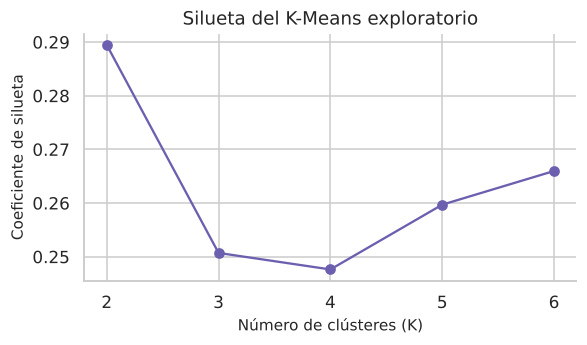

,silueta
K,
2,"0,289"
3,"0,251"
4,"0,248"
5,"0,260"
6,"0,266"


**Lectura.** La mayor silueta fue 0,289 con K = 2, y el rango observado fue de 0,248 a 0,289. Según Kaufman y Rousseeuw (1990), 0,289 corresponde a una estructura débil, que podría ser artificial, y valores menores que 0,25 indican que no hay estructura sustancial; la viabilidad del agrupamiento es, por tanto, **moderada a baja**. Como `rain_1h` y `snow_1h` son casi siempre 0, la segmentación se apoya en temperatura, nubosidad, volumen y hora; la selección de variables y el segundo algoritmo (DBSCAN o jerárquico) serán determinantes en la Fase 3. Este chequeo no sustituye el análisis de agrupamiento completo.

In [23]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

X = df_eda[["temp_c", "clouds_all", "traffic_volume"]].copy()
X["hora_sin"] = np.sin(2 * np.pi * df_eda["hora"] / 24)
X["hora_cos"] = np.cos(2 * np.pi * df_eda["hora"] / 24)
X = X.dropna()
muestra = X.sample(n=min(8000, len(X)), random_state=SEED)
Xs = StandardScaler().fit_transform(muestra)

sil = {}
for k in range(2, 7):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Xs)
    sil[k] = silhouette_score(Xs, etiquetas)
sil = pd.Series(sil, name="silueta")

fig, ax = plt.subplots(figsize=(5.5, 3.3))
ax.plot(sil.index, sil.values, marker="o", color=COLOR)
ax.set_title("Silueta del K-Means exploratorio"); ax.set_xlabel("Número de clústeres (K)"); ax.set_ylabel("Coeficiente de silueta")
ax.set_xticks(sil.index); plt.tight_layout(); plt.show()

kmax = sil.idxmax()
display(sil.rename("silueta").to_frame().rename_axis("K").style.format(lambda v: fmt(v, 3)))
def interpreta_silueta(s):
    # Rangos de Kaufman y Rousseeuw (1990)
    if s >= 0.71: return "una estructura fuerte"
    if s >= 0.51: return "una estructura razonable"
    if s >= 0.26: return "una estructura débil, que podría ser artificial"
    return "ausencia de estructura sustancial"

viab = "alta" if sil.max() >= 0.51 else ("moderada a baja" if sil.max() >= 0.26 else "baja")
nota(f"**Lectura.** La mayor silueta fue {fmt(sil.max(),3)} con K = {kmax}, y el rango observado fue de {fmt(sil.min(),3)} a {fmt(sil.max(),3)}. "
     f"Según Kaufman y Rousseeuw (1990), {fmt(sil.max(),3)} corresponde a {interpreta_silueta(sil.max())}, y valores menores que 0,25 indican que no hay estructura sustancial; "
     f"la viabilidad del agrupamiento es, por tanto, **{viab}**. Como `rain_1h` y `snow_1h` son casi siempre 0, la segmentación se apoya en temperatura, nubosidad, volumen y hora; "
     "la selección de variables y el segundo algoritmo (DBSCAN o jerárquico) serán determinantes en la Fase 3. Este chequeo no sustituye el análisis de agrupamiento completo.")


---
# 6. Conclusiones del EDA y decisiones para la Fase 2

In [24]:
resumen = pd.DataFrame([
    ["Duplicados exactos", f"{fmt(n_exactos,0)} filas", "Eliminar."],
    ["Horas repetidas con contenido distinto", f"{fmt(n_ts_distintos,0)} filas", "Conservar un registro por hora (el primero)."],
    ["Valores imposibles (temp = 0 K, lluvia > 100 mm/h)", f"{int(mask_imp.sum())} registros", "Convertir a faltantes, analizar el mecanismo de falta e imputar con justificación."],
    ["Horas ausentes de la serie", f"{fmt(len(ausentes)/len(rango_completo)*100,1)} % de las horas esperadas", "No imputar; evitar rezagos ingenuos; declarar la limitación."],
    ["Asimetría fuerte en lluvia y nieve", f"asimetría lluvia = {fmt(desc.loc['rain_1h','asimetría'])}, nieve = {fmt(desc.loc['snow_1h','asimetría'])}", "Transformación log1p; conservar los eventos reales."],
    ["Efecto del calendario", f"η² mayor = {asoc.index[0]} ({fmt(asoc.iloc[0]['η²']*100,1)} %)", "Variables derivadas: hora, día, mes, fin de semana, festivo propagado al día."],
    ["Interacción hora × tipo de día", "perfiles laboral y fin de semana distintos", "Variables derivadas (fin de semana, hora pico) y modelos capaces de capturar interacciones."],
    ["Nivel de tráfico", f"razón mayoritaria/minoritaria = {fmt(ratio,2)}", "Partición estratificada 70/15/15; evaluar `class_weight` si hace falta."],
    ["Clustering", f"mejor silueta exploratoria = {fmt(sil.max(),3)} (K = {kmax})", "Elegir variables con cuidado; K-Means + segundo algoritmo en la Fase 3."],
], columns=["Hallazgo", "Evidencia (calculada arriba)", "Decisión para la Fase 2 / 3"])
display(resumen.style.hide(axis="index"))

Hallazgo,Evidencia (calculada arriba),Decisión para la Fase 2 / 3
Duplicados exactos,17 filas,Eliminar.
Horas repetidas con contenido distinto,7.612 filas,Conservar un registro por hora (el primero).
"Valores imposibles (temp = 0 K, lluvia > 100 mm/h)",11 registros,"Convertir a faltantes, analizar el mecanismo de falta e imputar con justificación."
Horas ausentes de la serie,"22,8 % de las horas esperadas",No imputar; evitar rezagos ingenuos; declarar la limitación.
Asimetría fuerte en lluvia y nieve,"asimetría lluvia = 28,64, nieve = 65,91",Transformación log1p; conservar los eventos reales.
Efecto del calendario,"η² mayor = hora (78,2 %)","Variables derivadas: hora, día, mes, fin de semana, festivo propagado al día."
Interacción hora × tipo de día,perfiles laboral y fin de semana distintos,"Variables derivadas (fin de semana, hora pico) y modelos capaces de capturar interacciones."
Nivel de tráfico,"razón mayoritaria/minoritaria = 1,36",Partición estratificada 70/15/15; evaluar `class_weight` si hace falta.
Clustering,"mejor silueta exploratoria = 0,289 (K = 2)",Elegir variables con cuidado; K-Means + segundo algoritmo en la Fase 3.


**Respuesta preliminar a las preguntas de investigación** (calculada en la celda siguiente)

In [25]:
top_cal = asoc.drop(index=["weather_grupo", "anio"]).index[0]
nota(f"""
- **Pregunta secundaria 1 (patrones).** El factor de calendario con mayor η² es `{top_cal}` ({fmt(asoc.loc[top_cal,'η²']*100,1)} % de la varianza). 
  Los perfiles horarios laboral y de fin de semana tienen picos en {hora_pico_lab}:00 h y {hora_pico_fin}:00 h respectivamente (sección 5.3).
- **Pregunta secundaria 2 (clima).** El tipo de clima explica {fmt(clima,1)} % de la varianza del volumen y la mayor |Spearman| meteorológica es {fmt(max_clima)}; 
  su aporte neto debe evaluarse en los modelos controlando la hora y el día.
- **Pregunta secundaria 3 (niveles y segmentos).** Distribución de niveles: {fmt(dist.loc['bajo','%'],1)} % / {fmt(dist.loc['medio','%'],1)} % / {fmt(dist.loc['alto','%'],1)} % (bajo/medio/alto); 
  mejor silueta exploratoria {fmt(sil.max(),3)} (K = {kmax}).
- **Pregunta principal.** La medición cuantitativa de la capacidad predictiva se realiza con el baseline de la Fase 2 y los modelos de la Fase 3; 
  este EDA identifica los factores candidatos (calendario primero, clima como complemento si el η² lo respalda).
""")


- **Pregunta secundaria 1 (patrones).** El factor de calendario con mayor η² es `hora` (78,2 % de la varianza). 
  Los perfiles horarios laboral y de fin de semana tienen picos en 16:00 h y 13:00 h respectivamente (sección 5.3).
- **Pregunta secundaria 2 (clima).** El tipo de clima explica 2,1 % de la varianza del volumen y la mayor |Spearman| meteorológica es 0,14; 
  su aporte neto debe evaluarse en los modelos controlando la hora y el día.
- **Pregunta secundaria 3 (niveles y segmentos).** Distribución de niveles: 27,2 % / 37,0 % / 35,8 % (bajo/medio/alto); 
  mejor silueta exploratoria 0,289 (K = 2).
- **Pregunta principal.** La medición cuantitativa de la capacidad predictiva se realiza con el baseline de la Fase 2 y los modelos de la Fase 3; 
  este EDA identifica los factores candidatos (calendario primero, clima como complemento si el η² lo respalda).


**Limitaciones que se declaran desde ahora**

1. Una sola estación de conteo y un solo sentido (westbound): los resultados no se generalizan a otros tramos.
2. La serie tiene huecos largos; las conclusiones son de calendario y clima, no de pronóstico continuo.
3. Una partición aleatoria de una serie horaria deja horas vecinas en entrenamiento y prueba y puede dar métricas optimistas; en la Fase 2 se documenta y se complementa con una validación temporal.
4. Los umbrales del nivel de tráfico (1.500 y 4.500) se fijaron observando la distribución completa del volumen; son una decisión de diseño, no un resultado independiente de los datos.

**Referencias.** Véase la sección 8.

---
# 7. Lista de verificación frente a la guía (Entregable 1)

| Requisito de la guía | Dónde se cumple |
|---|---|
| Dataset de repositorio permitido, > 600 filas, ≥ 5 variables de distintos tipos | Sección 2 (ficha técnica y tabla de requisitos) |
| Contextualización e impacto de la solución | Sección 1.1 |
| 1 pregunta principal y 3 secundarias | Sección 1.2 |
| 1 objetivo general y 3 específicos en formato SMART | Sección 1.3 |
| Nombre, repositorio, URL, fecha de extracción y licencia | Sección 2 |
| Diccionario de datos (tipo, descripción, rango) | Sección 2 |
| Univariado: tendencia central, dispersión, asimetría y curtosis; frecuencias | Sección 4 |
| Bivariado y multivariado: correlación (Pearson y Spearman), dispersión, χ² | Sección 5 |
| Calidad: % de faltantes, outliers (IQR y Z-score), incoherencias y duplicados | Sección 3 |

---
# 8. Referencias (APA, 7.ª edición)

Cochran, W. G. (1954). Some methods for strengthening the common χ² tests. *Biometrics, 10*(4), 417–451. https://doi.org/10.2307/3001616

Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.

Cramér, H. (1946). *Mathematical methods of statistics*. Princeton University Press.

Hogue, J. (2019). *Metro Interstate Traffic Volume* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5X60B

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Kaufman, L., y Rousseeuw, P. J. (1990). *Finding groups in data: An introduction to cluster analysis*. John Wiley & Sons.

Kruskal, W. H., y Wallis, W. A. (1952). Use of ranks in one-criterion variance analysis. *Journal of the American Statistical Association, 47*(260), 583–621. https://doi.org/10.1080/01621459.1952.10483441

McKinney, W. (2010). Data structures for statistical computing in Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 56–61). https://doi.org/10.25080/Majora-92bf1922-00a

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., y Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63*(3), 581–592. https://doi.org/10.1093/biomet/63.3.581

Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.

Universidad de La Salle, Facultad de Ingeniería. (2026). *Guía técnica detallada: Proyecto integrador de Ciencia de Datos e Inteligencia Artificial* [Documento institucional]. Maestría en Inteligencia Artificial.

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*, 261–272. https://doi.org/10.1038/s41592-019-0686-2

Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021